<a href="https://colab.research.google.com/github/QuirozAlaniz/Arbol_decision/blob/main/Tarea_Regresion_California_Housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Actividad: Árbol de Decisión para Regresión
\
Objetivo
\
Analizar el comportamiento de un modelo de árbol de decisión en un problema de regresión, evaluando su capacidad de generalización mediante el estudio del sobreajuste, la profundidad del árbol y la poda.



Dataset
Se utilizará el dataset California Housing, disponible en scikit-learn.

 Instrucciones
1. Carga y exploración de datos
Cargar el dataset en un DataFrame

Identificar la variable objetivo (MedHouseVal)

Analizar la estructura del dataset (info, describe)

Visualizar la distribución de la variable objetivo

In [31]:
from sklearn.datasets import fetch_california_housing
# scikit-learn: preprocesamiento y partición
from sklearn.model_selection import train_test_split

# cargar el dataset
bunch_data = fetch_california_housing(as_frame=True)
df = bunch_data.frame

# scikit-learn: árbol de regresión
from sklearn.tree import DecisionTreeRegressor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# scikit-learn: métricas
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score)

# ─── Importaciones ───────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns



# scikit-learn: preprocesamiento y partición
from sklearn.model_selection import train_test_split

# scikit-learn: árbol de regresión
from sklearn.tree import DecisionTreeRegressor

# scikit-learn: métricas
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)



In [32]:
#Analizamos  la estructura del dataset
print( df.info() )
print()
print()
print ( df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None


             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      

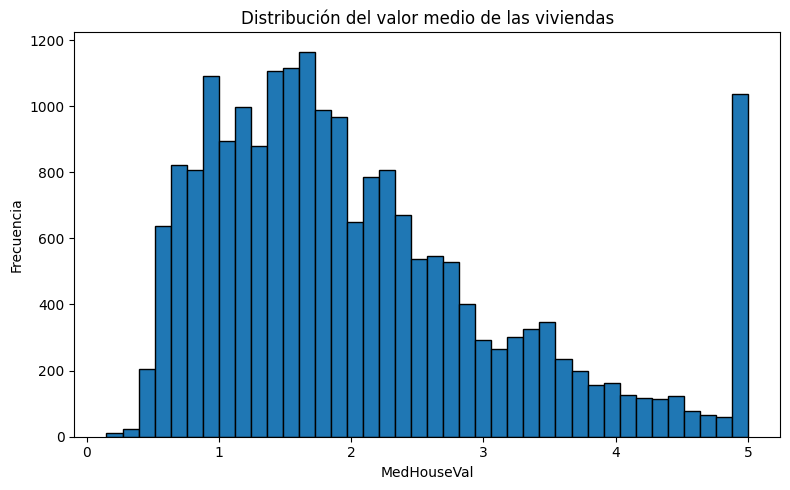

In [33]:
plt.figure(figsize=(8, 5))
plt.hist(df["MedHouseVal"], bins=40, edgecolor="black")
plt.title("Distribución del valor medio de las viviendas")
plt.xlabel("MedHouseVal")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

En el gráfico podemos ver la distribución de la variable MedHouseVal, que expresa el valor medio de las viviendas en California

2. Preparación de datos
Definir:

X: variables predictoras

y: variable objetivo

Dividir los datos en entrenamiento (80%) y prueba (20%)

In [34]:
#Separamos las variables predictoras
X = df.drop("MedHouseVal", axis = 1)
y = df["MedHouseVal"]

In [35]:
#Dividimos los datos en entrenamiento 80 y 20 porciento
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42) # 80% entrenamiento, 20% prueba

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


3. Modelo base
Entrenar un árbol de decisión sin restricciones (max_depth=None)

Evaluar el modelo usando:

RMSE

R²

Comparar desempeño en entrenamiento y prueba

Determinar si existe sobreajuste



In [36]:
arbol_base = DecisionTreeRegressor(random_state=42) # Sin max_depth → crece hasta hojas puras (overfitting)

arbol_base.fit(X_train, y_train)

print("Profundidad:", arbol_base.get_depth())
print("Número de hojas:", arbol_base.get_n_leaves())
print("Número de nodos:", arbol_base.tree_.node_count)

Profundidad: 34
Número de hojas: 15854
Número de nodos: 31707


In [37]:
# ─── 4.1 Función de evaluación ───────────────────────────────────────────────
def evaluar_modelo(modelo, X_tr, y_tr, X_te, y_te, nombre='Modelo'):
    """Calcula RMSE, MAE y R² para train y test."""
    y_pred_tr = modelo.predict(X_tr)
    y_pred_te = modelo.predict(X_te)

    resultados = {
        'nombre':    nombre,
        'RMSE_train': np.sqrt(mean_squared_error(y_tr, y_pred_tr)),
        'RMSE_test':  np.sqrt(mean_squared_error(y_te, y_pred_te)),
        'MAE_train':  mean_absolute_error(y_tr, y_pred_tr),
        'MAE_test':   mean_absolute_error(y_te, y_pred_te),
        'R2_train':   r2_score(y_tr, y_pred_tr),
        'R2_test':    r2_score(y_te, y_pred_te),
    }
    return resultados

from IPython.display import display, Markdown

def imprimir_metricas(res):
    gap_rmse = res['RMSE_test'] - res['RMSE_train']





    md = f"""
### Métricas: {res['nombre']}

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | {res['RMSE_train']:.4f} | {res['RMSE_test']:.4f} | Menor es mejor |
| **MAE**  | {res['MAE_train']:.4f}  | {res['MAE_test']:.4f}  | Error absoluto medio |
| **R²**   | {res['R2_train']:.4f}   | {res['R2_test']:.4f}   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** {gap_rmse:.4f}
"""
    display(Markdown(md))

# ─── 4.2 Evaluación del árbol base ───────────────────────────────────────────
res_base = evaluar_modelo(arbol_base, X_train, y_train, X_test, y_test, 'Árbol Base (sin restricciones)')
imprimir_metricas(res_base)



### Métricas: Árbol Base (sin restricciones)

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | 0.0000 | 0.7037 | Menor es mejor |
| **MAE**  | 0.0000  | 0.4547  | Error absoluto medio |
| **R²**   | 1.0000   | 0.6221   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** 0.7037


Podemos observar que al utilizar el árbol de decisión con el conjunto de datos con el que fue entrenado, las predicciones son perfectas, pues el RMSE es 0, el MAE es 0 y $R^2$ es 1, por lo que es una predicción perfecta.
\
Sin embargo, al evaluar las mismas métricas con el conjunto de datos de prueba obtenemos en RMSE un 0.7037 lo cual es muy alto.
\
Para MAE (Error absoluto medio) es .45, es decir es muy alto.
\
Finalmente para $R^2$ tenemos .6221, que quiere decir que el modelo explica la variabilidad en un 62.21%.

Claramente estamos viendo un caso de sobreajuste de modelo al no darle restricciones de profundidad al árbol

4. Análisis Bias–Variance
Entrenar múltiples modelos variando el parámetro max_depth de 1 a 21.

Graficar el error (RMSE) en entrenamiento y prueba

Identificar el punto donde el modelo generaliza mejor

In [38]:
#print("Profundidad:", arbol_base.get_depth())
#print("Número de hojas:", arbol_base.get_n_leaves())
#print("Número de nodos:", arbol_base.tree_.node_count)

arboles =[]
for i in range(1, 22):
  arbol = DecisionTreeRegressor(random_state = 42, max_depth = i)
  arbol.fit(X_train, y_train)
  profundidad = arbol.get_depth()
  hojas = arbol.get_n_leaves()
  nodos = arbol.tree_.node_count
  arboles.append(arbol)
print(arboles)

[DecisionTreeRegressor(max_depth=1, random_state=42), DecisionTreeRegressor(max_depth=2, random_state=42), DecisionTreeRegressor(max_depth=3, random_state=42), DecisionTreeRegressor(max_depth=4, random_state=42), DecisionTreeRegressor(max_depth=5, random_state=42), DecisionTreeRegressor(max_depth=6, random_state=42), DecisionTreeRegressor(max_depth=7, random_state=42), DecisionTreeRegressor(max_depth=8, random_state=42), DecisionTreeRegressor(max_depth=9, random_state=42), DecisionTreeRegressor(max_depth=10, random_state=42), DecisionTreeRegressor(max_depth=11, random_state=42), DecisionTreeRegressor(max_depth=12, random_state=42), DecisionTreeRegressor(max_depth=13, random_state=42), DecisionTreeRegressor(max_depth=14, random_state=42), DecisionTreeRegressor(max_depth=15, random_state=42), DecisionTreeRegressor(max_depth=16, random_state=42), DecisionTreeRegressor(max_depth=17, random_state=42), DecisionTreeRegressor(max_depth=18, random_state=42), DecisionTreeRegressor(max_depth=19, 

In [39]:
for i in arboles:
  model = evaluar_modelo(i, X_train, y_train, X_test, y_test, i)
  imprimir_metricas(model)


### Métricas: DecisionTreeRegressor(max_depth=1, random_state=42)

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | 0.9555 | 0.9717 | Menor es mejor |
| **MAE**  | 0.7427  | 0.7524  | Error absoluto medio |
| **R²**   | 0.3170   | 0.2795   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** 0.0161



### Métricas: DecisionTreeRegressor(max_depth=2, random_state=42)

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | 0.8559 | 0.8685 | Menor es mejor |
| **MAE**  | 0.6523  | 0.6601  | Error absoluto medio |
| **R²**   | 0.4520   | 0.4244   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** 0.0126



### Métricas: DecisionTreeRegressor(max_depth=3, random_state=42)

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | 0.7860 | 0.8015 | Menor es mejor |
| **MAE**  | 0.5887  | 0.5978  | Error absoluto medio |
| **R²**   | 0.5379   | 0.5098   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** 0.0155



### Métricas: DecisionTreeRegressor(max_depth=4, random_state=42)

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | 0.7415 | 0.7645 | Menor es mejor |
| **MAE**  | 0.5455  | 0.5587  | Error absoluto medio |
| **R²**   | 0.5887   | 0.5540   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** 0.0229



### Métricas: DecisionTreeRegressor(max_depth=5, random_state=42)

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | 0.6959 | 0.7242 | Menor es mejor |
| **MAE**  | 0.5063  | 0.5223  | Error absoluto medio |
| **R²**   | 0.6377   | 0.5997   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** 0.0283



### Métricas: DecisionTreeRegressor(max_depth=6, random_state=42)

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | 0.6558 | 0.7052 | Menor es mejor |
| **MAE**  | 0.4734  | 0.5008  | Error absoluto medio |
| **R²**   | 0.6782   | 0.6205   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** 0.0494


... (11 outputs left out)


### Métricas: DecisionTreeRegressor(max_depth=18, random_state=42)

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | 0.1261 | 0.6930 | Menor es mejor |
| **MAE**  | 0.0502  | 0.4465  | Error absoluto medio |
| **R²**   | 0.9881   | 0.6335   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** 0.5670



### Métricas: DecisionTreeRegressor(max_depth=19, random_state=42)

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | 0.0985 | 0.7099 | Menor es mejor |
| **MAE**  | 0.0346  | 0.4546  | Error absoluto medio |
| **R²**   | 0.9927   | 0.6154   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** 0.6114



### Métricas: DecisionTreeRegressor(max_depth=20, random_state=42)

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | 0.0757 | 0.6994 | Menor es mejor |
| **MAE**  | 0.0230  | 0.4494  | Error absoluto medio |
| **R²**   | 0.9957   | 0.6268   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** 0.6237



### Métricas: DecisionTreeRegressor(max_depth=21, random_state=42)

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | 0.0579 | 0.7100 | Menor es mejor |
| **MAE**  | 0.0148  | 0.4553  | Error absoluto medio |
| **R²**   | 0.9975   | 0.6154   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** 0.6520


In [40]:
lista_resultados = []

# 2. Recorrer la lista de árboles que ya entrenaste
for arbol in arboles:
    # Obtenemos la profundidad actual de este árbol específico
    profundidad_actual = arbol.get_depth()
    nombre_arbol = f"Árbol Max Depth {profundidad_actual}"

    # Evaluamos el modelo usando tu función (devuelve un diccionario)
    res_diccionario = evaluar_modelo(arbol, X_train, y_train, X_test, y_test, nombre=nombre_arbol)

    # Agregamos el diccionario a la lista
    lista_resultados.append(res_diccionario)

# 3. Convertir la lista de 21 diccionarios en un único DataFrame de Pandas
df_metricas = pd.DataFrame(lista_resultados)

# Visualizar el DataFrame estructurado
df_metricas

,nombre,RMSE_train,RMSE_test,MAE_train,MAE_test,R2_train,R2_test
0,Árbol Max Depth 1,0.955523,0.971666,0.742741,0.752372,0.316997,0.279511
1,Árbol Max Depth 2,0.855859,0.868483,0.652305,0.660083,0.452045,0.424406
2,Árbol Max Depth 3,0.785957,0.801505,0.588724,0.597828,0.537898,0.509763
3,Árbol Max Depth 4,0.741534,0.764464,0.545544,0.558741,0.588659,0.554029
4,Árbol Max Depth 5,0.695948,0.724234,0.506347,0.522259,0.637679,0.599732
5,Árbol Max Depth 6,0.655831,0.705184,0.473438,0.500804,0.678245,0.620513
6,Árbol Max Depth 7,0.615396,0.675711,0.439090,0.473161,0.716698,0.651570
7,Árbol Max Depth 8,0.566211,0.649650,0.396402,0.448169,0.760173,0.677928
8,Árbol Max Depth 9,0.517161,0.644258,0.357232,0.435680,0.799926,0.683253
9,Árbol Max Depth 10,0.469964,0.644568,0.319196,0.433203,0.834778,0.682948


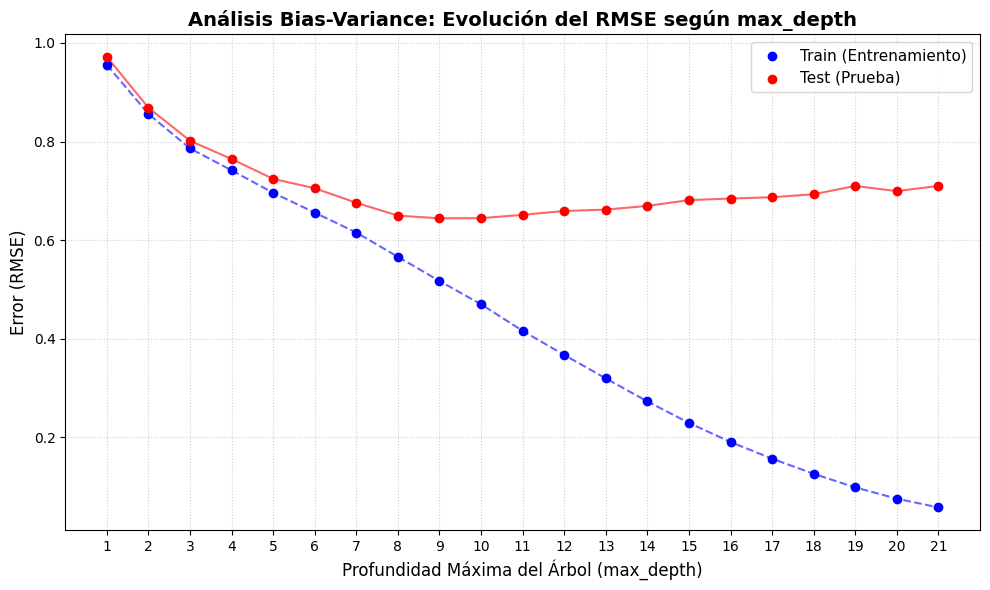

In [41]:
plt.figure(figsize=(10, 6))

# 2. Definir las profundidades del 1 al 21 basándonos en las filas del DataFrame
profundidades = df_metricas.index + 1

# 3. Graficar los puntos (Scatter Plot) y unirlos con líneas de tendencia
# Datos de entrenamiento (Train)
plt.scatter(profundidades, df_metricas["RMSE_train"], color='blue', label='Train (Entrenamiento)', zorder=5)
plt.plot(profundidades, df_metricas["RMSE_train"], color='blue', linestyle='--', alpha=0.6)

# Datos de prueba (Test)
plt.scatter(profundidades, df_metricas["RMSE_test"], color='red', label='Test (Prueba)', zorder=5)
plt.plot(profundidades, df_metricas["RMSE_test"], color='red', linestyle='-', alpha=0.6)

# 4. Personalizar el gráfico con etiquetas y títulos descriptivos
plt.title('Análisis Bias-Variance: Evolución del RMSE según max_depth', fontsize=14, fontweight='bold')
plt.xlabel('Profundidad Máxima del Árbol (max_depth)', fontsize=12)
plt.ylabel('Error (RMSE)', fontsize=12)

# Forzar al eje X a mostrar todos los números del 1 al 21 uno por uno
plt.xticks(profundidades)

# Añadir una cuadrícula de fondo limpia y la leyenda de colores
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)

# 5. Desplegar el gráfico final
plt.tight_layout()
plt.show()

5. Poda del árbol
Aplicar cost-complexity pruning (ccp_alpha)

Evaluar distintos valores de ccp_alpha con ccp_alphas = ccp_alphas[::5]

Analizar su efecto en el error del modelo

In [42]:
# 1. Obtener ruta de poda
from sklearn.tree import DecisionTreeRegressor

# Modelo base para obtener alphas
path = DecisionTreeRegressor(random_state=42).cost_complexity_pruning_path(X_train, y_train)

ccp_alphas = path.ccp_alphas

In [43]:
#2. Entrenar modelos con distintos niveles de poda
import numpy as np
from sklearn.metrics import mean_squared_error

rmse_train = []
rmse_test = []
alphas = []

ccp_alphas = ccp_alphas[::5]  # tomar cada 5

for alpha in ccp_alphas:
    model = DecisionTreeRegressor(random_state=42, max_depth = 10, ccp_alpha=alpha)
    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    rmse_train.append(np.sqrt(mean_squared_error(y_train, y_pred_train)))
    rmse_test.append(np.sqrt(mean_squared_error(y_test, y_pred_test)))
    alphas.append(alpha)

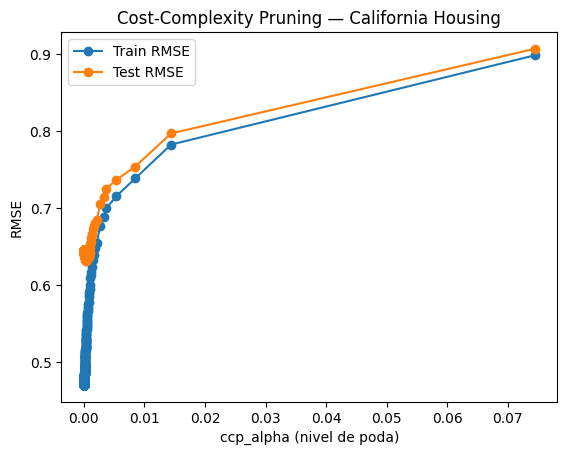

In [44]:
#3. Gráfica (poda vs error)
import matplotlib.pyplot as plt

plt.figure()
plt.plot(alphas, rmse_train, marker='o', label="Train RMSE")
plt.plot(alphas, rmse_test, marker='o', label="Test RMSE")

plt.xlabel("ccp_alpha (nivel de poda)")
plt.ylabel("RMSE")
plt.title("Cost-Complexity Pruning — California Housing")
plt.legend()
plt.show()

In [45]:
mejor_arbol = arboles[8]

importancias = pd.Series(mejor_arbol.feature_importances_, index=X.columns).sort_values(ascending=False)

print(importancias)

MedInc        0.631555
AveOccup      0.131729
Latitude      0.075473
Longitude     0.058643
HouseAge      0.043700
AveRooms      0.036752
Population    0.011276
AveBedrms     0.010872
dtype: float64


6. Interpretación de resultados
Responder de manera justificada:

¿El modelo base presenta sobreajuste? Explique

¿Cómo afecta la profundidad del árbol al error?

¿Qué efecto tiene la poda en el modelo?

¿Cuál configuración produce el mejor desempeño?

¿Qué variables son más relevantes según el modelo?

El modelo base presenta sobreajuste, podemos verlo en la tabla de métricas del modelo. En la columna Train el valor de RMSE	es de 0.0000	lo cual indica que no hay error, es un ajuste perfecto, el MAE es 0.0000, y el $R^2$ es 1.000, estos valores comprenden un ajuste perfecto, sin embargo con los datos de prueba obtenemos en RMSE 0.7037, MAE	0.4547 y R²	0.6221, lo cual indica un desempeño no tan bueno como con los datos de entrenamiento porque no generaliza bien.
\
\
La poda permite reducir el tamaño del árbol eliminando ramas que aportan poca capacidad predictiva. Al aumentar el valor de ccp_alpha, el árbol se vuelve más sencillo y reduce el sobreajuste.
\
\
La configuración que produce el mejor desempeño de acuerdo al $R^2=0.683253$ es el de profundidad 9. Con este nivel de profundidad el RMSE llega a 0.6443.
\
\
De acuerdo a la tabla obtenida con la función arbol.feature_importances, las variables más relevantes según el modelo son MedInc que indica el ingreso promedio, seguido de AveOccup que nos muestra la media de ocupación de la casa.